# Supply Chain Late Delivery Analysis & Prediction
**Dataset:** DataCo Smart Supply Chain (180,519 order lines, 2015–2018), public dataset on Mendeley Data (CC BY 4.0).

**Business question:** Which orders are delivered late, why, and can we flag high-risk orders at the moment they are placed so the operations team can act early?

Steps: 1) load & clean  2) data quality checks  3) SQL KPI analysis  4) visual EDA  5) predictive model using only information known at order time  6) findings.

In [1]:
import pandas as pd, numpy as np, sqlite3, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 140)
df = pd.read_csv("data/DataCoSupplyChainDataset.csv", encoding="latin-1")
print(df.shape)

(180519, 53)


## 1. Cleaning and data quality
Personal data columns (names, email, password, street) are dropped straight away — they are not needed and should not be processed (GDPR data minimisation).

In [2]:
pii = ["Customer Email","Customer Fname","Customer Lname","Customer Password","Customer Street","Product Description","Product Image"]
df = df.drop(columns=pii)
df["order_date"] = pd.to_datetime(df["order date (DateOrders)"], format="%m/%d/%Y %H:%M")
df["ship_date"]  = pd.to_datetime(df["shipping date (DateOrders)"], format="%m/%d/%Y %H:%M")
df["delay_days"] = df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]
quality = {
 "rows": len(df),
 "duplicate rows": int(df.duplicated().sum()),
 "missing Order Zipcode (%)": round(df["Order Zipcode"].isna().mean()*100,1),
 "cancelled / suspected fraud rows": int(df["Order Status"].isin(["CANCELED","SUSPECTED_FRAUD"]).sum()),
 "date range": f'{df.order_date.min():%d %b %Y} to {df.order_date.max():%d %b %Y}',
}
quality

{'rows': 180519,
 'duplicate rows': 0,
 'missing Order Zipcode (%)': np.float64(86.2),
 'cancelled / suspected fraud rows': 7754,
 'date range': '01 Jan 2015 to 31 Jan 2018'}

In [3]:
# Cancelled and fraud orders were never shipped normally, so they are excluded from delivery analysis.
# The last weeks of data (Oct 2017 onwards) contain almost no delivered orders, so the analysis window ends at Sept 2017.
print(df.groupby(df.order_date.dt.to_period("M")).size().tail(6))
d = df[~df["Order Status"].isin(["CANCELED","SUSPECTED_FRAUD"])].copy()
d = d[d.order_date < "2017-10-01"]
print("rows analysed:", len(d), "| distinct orders:", d["Order Id"].nunique())

order_date
2017-08    5305
2017-09    5189
2017-10    2255
2017-11    2055
2017-12    2124
2018-01    2123
Freq: M, dtype: int64


rows analysed: 164572 | distinct orders: 54854


## 2. KPI analysis in SQL

In [4]:
con = sqlite3.connect(":memory:")
d.rename(columns=lambda c: c.replace(" ","_").replace("(","").replace(")","")).to_sql("orders", con, index=False)
q = {}
q["kpi_overall"] = """
SELECT COUNT(DISTINCT Order_Id)                          AS orders,
       ROUND(100.0*AVG(Late_delivery_risk),1)            AS late_pct,
       ROUND(AVG(Days_for_shipping_real),2)              AS avg_actual_days,
       ROUND(AVG(Days_for_shipment_scheduled),2)         AS avg_promised_days,
       ROUND(SUM(Sales)/1e6,2)                           AS sales_m
FROM orders;"""
q["late_by_shipping_mode"] = """
SELECT Shipping_Mode,
       COUNT(*)                                          AS order_lines,
       ROUND(100.0*AVG(Late_delivery_risk),1)            AS late_pct,
       ROUND(AVG(Days_for_shipment_scheduled),1)         AS promised_days,
       ROUND(AVG(Days_for_shipping_real),1)              AS actual_days,
       ROUND(AVG(CASE WHEN delay_days>0 THEN delay_days END),2) AS avg_delay_when_late
FROM orders GROUP BY Shipping_Mode ORDER BY late_pct DESC;"""
q["late_by_market"] = """
SELECT Market, COUNT(*) AS order_lines, ROUND(100.0*AVG(Late_delivery_risk),1) AS late_pct,
       ROUND(SUM(Sales)/1e6,2) AS sales_m
FROM orders GROUP BY Market ORDER BY late_pct DESC;"""
q["worst_regions"] = """
SELECT Order_Region, COUNT(*) AS order_lines, ROUND(100.0*AVG(Late_delivery_risk),1) AS late_pct,
       RANK() OVER (ORDER BY AVG(Late_delivery_risk) DESC) AS late_rank
FROM orders GROUP BY Order_Region HAVING COUNT(*) > 1000 ORDER BY late_rank LIMIT 5;"""
q["profit_late_vs_ontime"] = """
SELECT CASE Late_delivery_risk WHEN 1 THEN 'Late' ELSE 'On time / early' END AS delivery,
       COUNT(*) AS order_lines, ROUND(AVG(Order_Profit_Per_Order),2) AS avg_profit_per_line
FROM orders GROUP BY 1;"""
res = {k: pd.read_sql(v, con) for k,v in q.items()}
open("sql/kpi_queries.sql","w").write("\n\n".join(f"-- {k}\n{v.strip()}" for k,v in q.items()))
for k,v in res.items(): print(f"\n### {k}\n", v.to_string(index=False))


### kpi_overall
  orders  late_pct  avg_actual_days  avg_promised_days  sales_m
  54854      57.3              3.5               2.93    32.79

### late_by_shipping_mode
  Shipping_Mode  order_lines  late_pct  promised_days  actual_days  avg_delay_when_late
   First Class        25270     100.0            1.0          2.0                 1.00
  Second Class        32188      79.8            2.0          4.0                 2.50
      Same Day         8851      47.7            0.0          0.5                 1.00
Standard Class        98263      39.8            4.0          4.0                 1.51

### late_by_market
       Market  order_lines  late_pct  sales_m
      Europe        45277      57.8     9.19
        USCA        24627      57.4     4.84
Pacific Asia        34205      57.3     6.74
       LATAM        49309      56.9     9.82
      Africa        11154      56.8     2.21

### worst_regions
   Order_Region  order_lines  late_pct  late_rank
Central Africa         1616      

## 3. Visual analysis

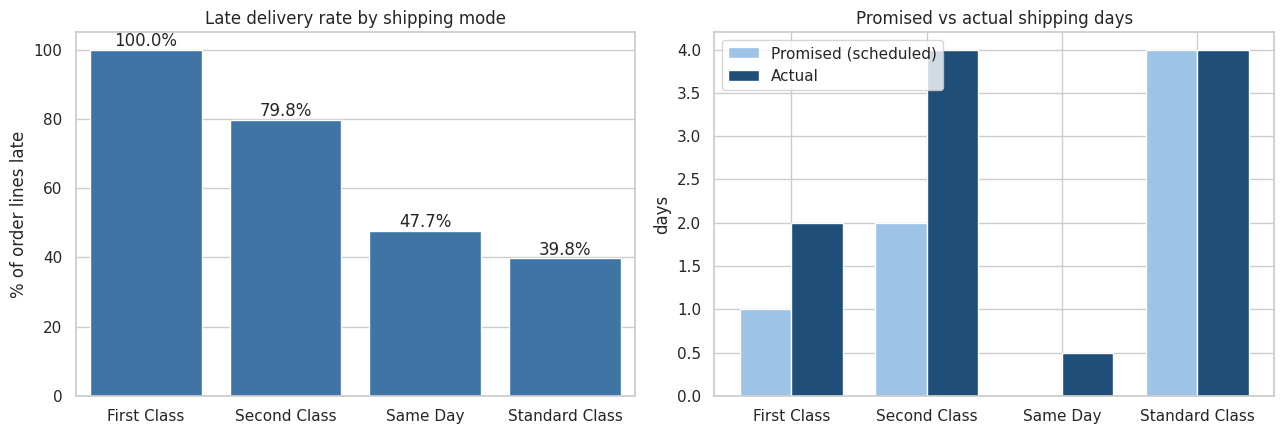

In [5]:
fig, ax = plt.subplots(1,2, figsize=(13,4.5))
m = res["late_by_shipping_mode"]
sns.barplot(data=m, x="Shipping_Mode", y="late_pct", ax=ax[0], color="#2E75B6")
ax[0].set(title="Late delivery rate by shipping mode", ylabel="% of order lines late", xlabel="")
for i,v in enumerate(m.late_pct): ax[0].text(i, v+1, f"{v}%", ha="center")
x = np.arange(len(m)); w=.38
ax[1].bar(x-w/2, m.promised_days, w, label="Promised (scheduled)", color="#9DC3E6")
ax[1].bar(x+w/2, m.actual_days, w, label="Actual", color="#1F4E79")
ax[1].set_xticks(x, m.Shipping_Mode); ax[1].set(title="Promised vs actual shipping days", ylabel="days"); ax[1].legend()
plt.tight_layout(); plt.savefig("charts/late_by_shipping_mode.png", dpi=150); plt.show()

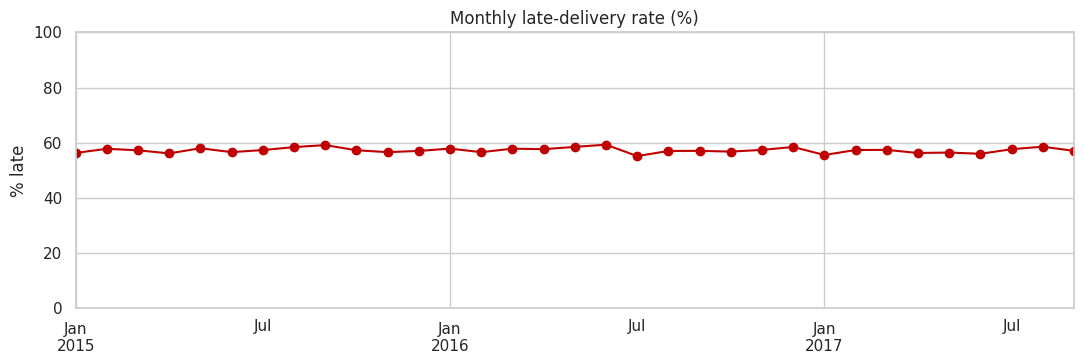

monthly late rate range: 55.2 to 59.3


In [6]:
monthly = d.set_index("order_date").resample("MS")["Late_delivery_risk"].mean()*100
ax = monthly.plot(figsize=(11,3.8), marker="o", color="#C00000")
ax.set(title="Monthly late-delivery rate (%)", ylabel="% late", xlabel="", ylim=(0,100))
plt.tight_layout(); plt.savefig("charts/monthly_late_rate.png", dpi=150); plt.show()
print("monthly late rate range:", round(monthly.min(),1), "to", round(monthly.max(),1))

## 4. Predicting late delivery at the time of order
**Leakage check:** actual shipping days, delivery status and shipping date are only known *after* shipping, so they are excluded. Only fields available when the order is placed are used.
**Time-based split:** the model is trained on older orders and tested on the most recent 20%, as it would be used in practice.

In [7]:
d["order_month"]=d.order_date.dt.month; d["order_dow"]=d.order_date.dt.dayofweek; d["order_hour"]=d.order_date.dt.hour
cat = ["Shipping Mode","Type","Market","Order Region","Customer Segment","Department Name","Category Name"]
num = ["Days for shipment (scheduled)","Order Item Quantity","Order Item Product Price","Order Item Discount Rate","Sales","order_month","order_dow","order_hour"]
d = d.sort_values("order_date")
cut = int(len(d)*0.8)
train, test = d.iloc[:cut], d.iloc[cut:]
Xtr, Xte, ytr, yte = train[cat+num], test[cat+num], train["Late_delivery_risk"], test["Late_delivery_risk"]
print("train:", train.order_date.min().date(), "->", train.order_date.max().date(), "| test:", test.order_date.min().date(), "->", test.order_date.max().date())

pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", StandardScaler(), num)])
baseline_acc = max(yte.mean(), 1-yte.mean())
models = {
 "Logistic Regression": Pipeline([("pre",pre),("m",LogisticRegression(max_iter=2000))]),
 "XGBoost": Pipeline([("pre",pre),("m",XGBClassifier(n_estimators=400,max_depth=6,learning_rate=0.08,subsample=0.9,colsample_bytree=0.8,eval_metric="logloss",random_state=42))]),
}
scores=[]
for name, mdl in models.items():
    mdl.fit(Xtr,ytr); p = mdl.predict_proba(Xte)[:,1]
    scores.append({"model":name,"ROC-AUC":round(roc_auc_score(yte,p),3),"accuracy":round(accuracy_score(yte,p>0.5),3)})
scores = pd.DataFrame(scores); print("Majority-class baseline accuracy:", round(baseline_acc,3)); scores

train: 2015-01-01 -> 2017-03-13 | test: 2017-03-13 -> 2017-09-30


Majority-class baseline accuracy: 0.57


,model,ROC-AUC,accuracy
0,Logistic Regression,0.746,0.705
1,XGBoost,0.780,0.719


In [8]:
best = models["XGBoost"]; p = best.predict_proba(Xte)[:,1]
print(classification_report(yte, p>0.5, digits=3))
# How useful is the risk score for operations? Late rate among the orders the model ranks as highest risk:
test = test.assign(risk=p)
test["risk_band"] = pd.qcut(test.risk.rank(method="first"), 5, labels=["Lowest 20%","2","3","4","Highest 20%"])
bands = test.groupby("risk_band", observed=True)["Late_delivery_risk"].mean().mul(100).round(1)
print("\nActual late rate by predicted risk band (%):\n", bands.to_string())

              precision    recall  f1-score   support

           0      0.624     0.871     0.727     14155
           1      0.861     0.603     0.710     18760

    accuracy                          0.719     32915
   macro avg      0.743     0.737     0.718     32915
weighted avg      0.759     0.719     0.717     32915


Actual late rate by predicted risk band (%):
 risk_band
Lowest 20%     32.6
2              39.0
3              41.2
4              74.2
Highest 20%    97.9


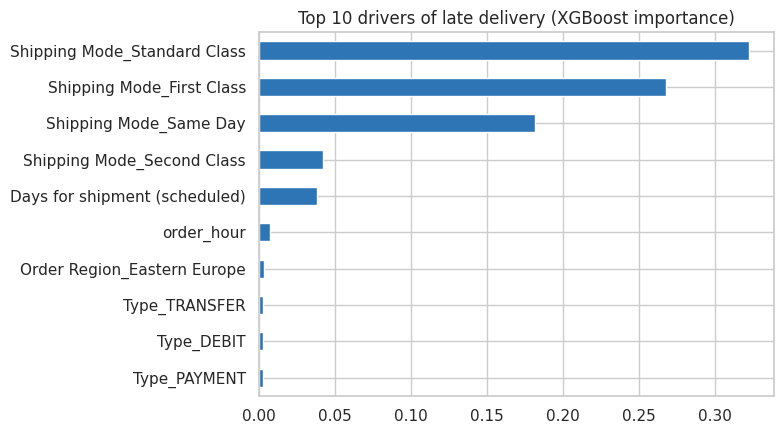

In [9]:
imp = pd.Series(best.named_steps["m"].feature_importances_, index=best.named_steps["pre"].get_feature_names_out())
imp.index = imp.index.str.replace("cat__","").str.replace("num__","")
top = imp.sort_values().tail(10)
ax = top.plot.barh(figsize=(8,4.5), color="#2E75B6"); ax.set(title="Top 10 drivers of late delivery (XGBoost importance)")
plt.tight_layout(); plt.savefig("charts/feature_importance.png", dpi=150); plt.show()

## 5. Findings (written from the results above)
See the README for the summary of results and recommendations.